In [ ]:
# Practical Pytorch : https://www.youtube.com/watch?v=3CJcziWrB3M&list=PLaKOkzuttbBk&index=1
#
# https://www.youtube.com/playlist?list=PLaKOkzuttbBk
import torch

x = torch.tensor([1, 2, 3]) 
x



tensor([1, 2, 3])

In [2]:
torch.__version__

'2.14.0'

In [3]:
x * 2

tensor([2, 4, 6])

In [5]:
torch.cuda.is_available()

False

In [ ]:
torch.backends.mps.is_available() # has an apple GPU

True

In [ ]:
# IMPORTANT : most errors are the .shape or the .dtype being WRONG

- scalar     : rank = 0
- vector     : rank = 1 : means you need one number to index
- matrix     : rank = 2 : needs 2 numbers to index
- 3-D tensor : rank 3 :

Rank is how many axes a tensor has

In [12]:
torch.zeros(2, 3)
torch.ones(2, 3)
torch.randn(2, 3).shape
# torch.tensor([1, 2, 3])

torch.Size([2, 3])

In [14]:
x = torch.zeros(2, 3, 4)
x

tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]]])

In [ ]:
x.shape 

# 2, 3, 4
# z, y, x

torch.Size([2, 3, 4])

# **dim** and **axis** mean the same thing

dim 0 = 2 planes

dim 1 = 3 rows

dim 2 = 4 columns


### From the OUTSIDE IN



In [20]:
x.ndim # number of dimension / axes

3

In [22]:
# underneath the hood it's just an array of 24 numbers - THAT is what make s reshape cheap
# the shape is just a representation / view

# 2 planes of 3 rows by 4 columns. torch.zeros(2, 3, 4)

x.dtype

torch.float32

In [25]:
x.reshape(6, 4)
#       cols, rows

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])

In [26]:
x.reshape(2, 12)

tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [27]:
x.reshape(12, 2)

tensor([[0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.]])

In [ ]:
print("shape:", x.shape)
print("dtype:", x.dtype)
print("ndim :", x.ndim)


shape: torch.Size([2, 3, 4])
dtype: torch.float32
ndim : 3


# Broadcasting!

- combining 2 tensors
- adding them cell by cell
- stretching different shapes to fit
- summing along an axis
- the matrix product

In [37]:
# 2 tensors with the same shape: 
# element-wise operation - shape A + shape A = shape A

a = torch.arange(1., 13.).reshape(3, 4)
b = torch.full((3, 4), 10)
# print(a)
# print(b)
print(a + b)
print((a + b).shape)


tensor([[11., 12., 13., 14.],
        [15., 16., 17., 18.],
        [19., 20., 21., 22.]])
torch.Size([3, 4])


In [40]:
a + b


tensor([[11., 12., 13., 14.],
        [15., 16., 17., 18.],
        [19., 20., 21., 22.]])

In [41]:
a * b

tensor([[ 10.,  20.,  30.,  40.],
        [ 50.,  60.,  70.,  80.],
        [ 90., 100., 110., 120.]])

In [42]:
a / b

tensor([[0.1000, 0.2000, 0.3000, 0.4000],
        [0.5000, 0.6000, 0.7000, 0.8000],
        [0.9000, 1.0000, 1.1000, 1.2000]])

In [39]:
a > b

tensor([[False, False, False, False],
        [False, False, False, False],
        [False, False,  True,  True]])

In [45]:
# BROADCASTING RULE 1 - a plane number can spread across any shape

a * 2

tensor([[ 2.,  4.,  6.,  8.],
        [10., 12., 14., 16.],
        [18., 20., 22., 24.]])

In [46]:
# ALWAYS pring the shape of any operation that mixes 2 tensors



In [47]:
# Summing over dimensions

x = torch.tensor([[1, 2, 3, 4],[5, 6, 7, 8],[9, 10, 11, 12]])

In [48]:
x

tensor([[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]])

In [ ]:
y = x.sum(dim=0) # dim 0 is 3 (it collapses) so we'll end up with size 4

y.shape

torch.Size([4])

In [ ]:
y = x.sum(dim=1) # dim 1 is 4 (it collapses) so we'll end up with size 3
y.shape

torch.Size([3])

In [ ]:
ones = torch.ones((2, 3, 4)) # --> (2, 3, 4)
ones

tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])

# Summing over different dimensions!  a.sum(dim=n)

### trick : take the dim out of the shape and thats the shape you get from the sum

In [68]:
print(ones.sum())

tensor(24.)


In [ ]:
print(ones.sum(dim=0)) # --> (3, 4) - the dim[0] = 2 is gone leaving shape (3, 4)

tensor([[2., 2., 2., 2.],
        [2., 2., 2., 2.],
        [2., 2., 2., 2.]])


In [70]:
print(ones.sum(dim=1)) # --> (2, 4) - the dim[1] = 3 is gone leaving (2, 4)

tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.]])


In [71]:
print(ones.sum(dim=2)) # --> (2, 3) - the dim[2] = 4 is gone leaving (2, 3)

tensor([[4., 4., 4.],
        [4., 4., 4.]])


In [72]:
x = torch.arange(1., 13.).reshape(3, 4)
x

tensor([[ 1.,  2.,  3.,  4.],
        [ 5.,  6.,  7.,  8.],
        [ 9., 10., 11., 12.]])

In [ ]:
x.sum(dim=0) # leaves 4

tensor([15., 18., 21., 24.])

In [76]:
x.sum(dim=1) # leaves 3

tensor([10., 26., 42.])

In [ ]:
x = torch.arange(1., 13.).reshape(3, 4)
print(x)
print(x.mean(dim=1))  # averages each row - BUT........ it comes out the wrong shape

tensor([[ 1.,  2.,  3.,  4.],
        [ 5.,  6.,  7.,  8.],
        [ 9., 10., 11., 12.]])
tensor([ 2.5000,  6.5000, 10.5000])


In [89]:
print(x.mean(dim=1)) # the ndim changes
print("below is the correct shape - we are averaging the row") # the columns collapse
print(x.mean(dim=1, keepdim=True)) # this is the one you want... the ndim STAYS THE SAME
print()
print(x.mean(dim=1, keepdim=True).shape)

tensor([ 2.5000,  6.5000, 10.5000])
below is the correct shape - we are averaging the row
tensor([[ 2.5000],
        [ 6.5000],
        [10.5000]])

torch.Size([3, 1])


In [ ]:
print(x - x.mean(dim=1, keepdim=True))


tensor([[-1.5000, -0.5000,  0.5000,  1.5000],
        [-1.5000, -0.5000,  0.5000,  1.5000],
        [-1.5000, -0.5000,  0.5000,  1.5000]])


#### Use keepdim=True whenever the result of a reduction goes back into the tensor it came from

In [92]:
# (3, 1) against (3, 4) has a 1 to stretch so it broadcasts.

## Matmul

In [ ]:
# the matrix product!
# a * a is NOT a Matmul
# @ is Matmul

s = torch.tensor([[1., 2.], [3, 4]])
print(s * s)
print(s @ s)

# * multiplies cell by cell

# @ is the matric product: a row * a column,  added up
# the middle dimensions must be the same : 
# the dims of the operation : (3, 4) @ (4, 2) = (3, 2)  Note : the 4 drops out

# matmul joins the shared axis - the outer dimensions survive

tensor([[ 1.,  4.],
        [ 9., 16.]])
tensor([[ 7., 10.],
        [15., 22.]])


In [ ]:
# shifted = scores + bias.        # broadcasting
# per_row = shifted.mean(dim=1)   # reduction 
# out     = scores @ W            # Matmul

## Rules
### Elementwise keeps the shape : a + b
### Broadcasting lines the shapes up from the right and stretches a 1
### A Reduction removes the axis you name : x.sum(dim=1)
### Matmul joins the shared axis and keeps the outer dimensions : (3,4) @ (4,2) has dim (3, 2)


In [97]:
# cpu has RAM
# gpu has VRAM
# PCIe bus connects the 2

x.device

device(type='cpu')

In [99]:
x = x.to("cpu")
# x = x.to("cuda:0")

In [ ]:
# one liner to pic the device : 
device = ("cuda" if torch.cuda.is_available() 
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print(device)
#     x = x.to(device)
#     y = y.to(device)

mps


In [105]:
device = ('cuda' if torch.cuda.is_available()
else 'mps' if torch.backends.mps.is_available()
else 'cpu')
print('device: ', device)

device:  mps


# Autograd !

In [ ]:
# y = w * x + b
# loss (y - t) ** 2

# .require_grad=True

# forward pass builds a graph and calc's the loss

# backward() fills the gradients by applying the chain rule to get the partial derivatives wrt the loss

# Leavs get .grad and no_grad ops out

In [109]:
w = torch.tensor(3.0, requires_grad=True)
x = torch.tensor(2.0) # data - no grad.    INPUT
b = torch.tensor(1.0, requires_grad=True)
t = torch.tensor(10.0) #                   TARGET 

y = w * x + b          # observed
y

tensor(7., grad_fn=<AddBackward0>)

In [110]:
# calc the loss

loss = (y - t) ** 2
loss

tensor(9., grad_fn=<PowBackward0>)

In [ ]:
print(y)
print(loss)
# end of the forward pass!

tensor(7., grad_fn=<AddBackward0>)
tensor(9., grad_fn=<PowBackward0>)


In [112]:
loss.backward()
print(w.grad)
print(b.grad)

tensor(-12.)
tensor(-6.)


In [ ]:
# also...
with torch.no_grad():
    z = w * x + b

## Loss Functions

1. mean squared for data : MSE
2. cross-entropy for classification - scored on logits

```
loss = loss_fun(prediction, target)

```

silent bug :  logits, not probabilities

In [ ]:
import torch.nn.functional as F  # where the loss functoins live
pred = torch.tensor([2.5, 0, 2.1, 7.8])
target = torch.tensor([3.0, -0.5, 2.0, 7.0])
F.mse_loss(pred, target) # reduction = 'mean' turns 4 numbers into 1

tensor(0.2875)

In [ ]:
# classification

# a logit is a score not a probability

logits = torch.tensor([2.0, 0.5, 0.1]) # class 0 is the truth
label = torch.tensor([0])  # the label is class 0 - the first one
F.cross_entropy(logits, label)

# cross entropy runs SOFTMAX which score the probability landed on the true class

# tensor(0.3168)

tensor(0.3168)

In [118]:
probs = F.softmax(logits, dim=0)
probs

tensor([0.7285, 0.1625, 0.1090])

In [ ]:
# class 0 holds 0.73 of the probability
# cross_entropy does softmax for you

In [ ]:
# the silent BUG : 
# the mistake : passing probabilities NOT logits to cross_entropy
F.cross_entropy(probs, label)

# tensor(0.7448) -- wrong
# where it should be tensor(0.3168) where we correctly passed the logits in 
# tensor(0.3168) -- correct

tensor(0.7448)

In [123]:
# the mistake : passing probabilities NOT logits to cross_entropy
F.cross_entropy(probs, label)

# gives tensor(0.7448)
# where it should be tensor(0.3168) where we correctly passed the logits in 

tensor(0.7448)

### Optimizers: SGD, Adam and the Learning Rate

1. the optimizer step : $w \leftarrow w - lr * grad$
2.  the learning rate - how far each step goes
3. when the rate is wrong (overfitting, underfitting)
4. Momentum and Adam - the safe default


In [ ]:
w = torch.tensor([1.0], requires_grad=True)
loss = 0.9 * (w - 5)**2
loss.backward()

print(w.grad)               # the slope of w =1.0
(w - 0.3 * w.grad).item()   # (w - lr * grad) by hand

tensor([-7.2000])


3.1600000858306885

In [ ]:
# Above is equalivalent to. : 
w = torch.tensor([1.0], requires_grad=True)

# SGD : Stochastic Gradient Descent

opt = torch.optim.SGD([w], lr=0.3)

loss = 0.9 * (w - 5)**2
loss.backward()      # fills w.grad
opt.step()           # w <-- w - lr * w.grad, now 3.16

In [127]:
for step in range(5):
    loss = 0.9 * (w-5)**2.  # mean squared
    opt.zero_grad()         # clear so it doest add to LAST STEP's grads
    loss.backward()         # compute the step's gradient
    opt.step()              # take the step down the loss curve - gradient descent

In [ ]:
# Tools to make chosing the learning rate easier : Momentum and Adam

opt = torch.optim.SGD([w], lr=0.1, momentum=0.9)  # moves faster through flat sections

opt = torch.optim.Adam([w], lr=1e-3)  # .001 <-- most common default

# Adam adapts weights from recent gradients - makes it more forgiving
# This is the default most projects start from!  

In [ ]:
opt.step() # w = w - lr * grad

# Adam lr=1e-3 is a good default


## The TRAINING LOOP

### 5 steps
1. forward
2. loss
3. zero grad
4. backward
5. step


In [ ]:
# the forward pass runs the model:

pred = x @ w + b

In [ ]:
# loss compares the guess to the target

loss = ((pred - y)**2).mean() # MSE

In [ ]:
# zero the old grad

opt.zero_grad()

In [ ]:
# runs autograd - values the gradients

# the grad is "the slope of the loss for each weight"
 
loss.backward()

In [ ]:
# nudges each weight so it lowers the loss
# w = w - lr * grad

opt.step()

In [137]:
# the loop : 
x = torch.linspace(-1, 1, 8).unsqueeze(1)  # 8 points
y = 2 * x + 1                              # the line to learn

w = torch.zeros(1, requires_grad=True)  # start at zero
b = torch.zeros(1, requires_grad=True)

opt = torch.optim.SGD([w, b], lr=0.3)      # SGD, the step rule   


In [138]:
# first pytorch training loop!

for epoch in range(6):
    pred = x @ w + b                        # 1. forward - model makes its guess
    loss = ((pred - y) ** 2).mean()         # 2. loss - how bad was the guess?
    opt.zero_grad()                         # 3. zero grad
    loss.backward()                         # 4. backward
    opt.step()                              # 5. step down the grad toward zero
    print(f"epoch {epoch}: loss = {loss:.4f}")

print(f"learned w = {w.item():.3f}  b = {b.item():.3f}")


epoch 0: loss = 2.7143
epoch 1: loss = 1.8743
epoch 2: loss = 1.7399
epoch 3: loss = 1.7184
epoch 4: loss = 1.7149
epoch 5: loss = 1.7144
learned w = 0.000  b = 0.996


## Epoch vs Iteration

#### iteration = one batch throught the loop - one opt.step()

#### epoch = one full pass over _all_ the training data

## Linear Regression from scratch
### A model is Tensors, a loss and the loop

1. The model is 2 tensors w and b, requires_grad=True



In [ ]:
import torch

torch.manual_seed(0)                   # so the run reproduces
x = torch.linspace(0.0, 4.00, 12)      # 12 inputs
y = 2 * x + 1 + 0.6 * torch.randn(12)  # the true line plus noise

w = torch.zeros(1, requires_grad=True) # the slope
b = torch.zeros(1, requires_grad=True) # the intercept
opt = torch.optim.SGD([w, b], lr=0.01) # SGD the step 

In [4]:
for epoch in range(201):
    pred = x * w + b                        # 1. forward 
    loss = ((pred - y) ** 2).mean()         # 2. loss 
    opt.zero_grad()                         # 3. zero grad
    loss.backward()                         # 4. backward
    opt.step()                              # 5. step 
    print(f"epoch {epoch}: loss = {loss:.4f}")

print(f"learned w = {w.item():.3f}  b = {b.item():.3f}.  (true w=2, b=1)")

epoch 0: loss = 0.3530
epoch 1: loss = 0.3530
epoch 2: loss = 0.3530
epoch 3: loss = 0.3530
epoch 4: loss = 0.3530
epoch 5: loss = 0.3530
epoch 6: loss = 0.3530
epoch 7: loss = 0.3530
epoch 8: loss = 0.3530
epoch 9: loss = 0.3529
epoch 10: loss = 0.3529
epoch 11: loss = 0.3529
epoch 12: loss = 0.3529
epoch 13: loss = 0.3529
epoch 14: loss = 0.3529
epoch 15: loss = 0.3529
epoch 16: loss = 0.3529
epoch 17: loss = 0.3529
epoch 18: loss = 0.3529
epoch 19: loss = 0.3529
epoch 20: loss = 0.3529
epoch 21: loss = 0.3529
epoch 22: loss = 0.3529
epoch 23: loss = 0.3529
epoch 24: loss = 0.3529
epoch 25: loss = 0.3529
epoch 26: loss = 0.3529
epoch 27: loss = 0.3528
epoch 28: loss = 0.3528
epoch 29: loss = 0.3528
epoch 30: loss = 0.3528
epoch 31: loss = 0.3528
epoch 32: loss = 0.3528
epoch 33: loss = 0.3528
epoch 34: loss = 0.3528
epoch 35: loss = 0.3528
epoch 36: loss = 0.3528
epoch 37: loss = 0.3528
epoch 38: loss = 0.3528
epoch 39: loss = 0.3528
epoch 40: loss = 0.3528
epoch 41: loss = 0.3528
ep

In [5]:
### Note where the loss flattens out - or CONVERGES to a value
x

tensor([0.0000, 0.3636, 0.7273, 1.0909, 1.4545, 1.8182, 2.1818, 2.5455, 2.9091,
        3.2727, 3.6364, 4.0000])

## nn.Model, Layers, Activations (video 10)
1. From w*x + b to `nn.Linear`
2. stacking layers `nn.Sequential` - a ReLU between them
3. Activations `r=ReLu, sigmoid, softmax`
4. Why the nonlinearity earns its place - two linears are one linear

In [ ]:
layer1 = nn.Linear(784, 128) # 784 in, 128 out (w and b are internal, requires_grad=True)

layer2 = nn.Linear(128, 10)

In [ ]:
model = nn.Sequential(
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

model.parameters()


## Datasets, DataLoaders, Batching (video 11)
1. The DataSet `__len__ and __getitem__`
2. The DataLoader `shuffle, collect, iterate`
3. The Batch dimension B `4 items --> (4, 1, 28, 28)`
4. The last bacth - what to do when it doesn't divide evenly?


In [ ]:
from torch.utils.data import Dataset

class TinyImages(Dataset):
    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return self.images[i], self.labels[i]

In [ ]:
from torch.utils.data import DataLoader

loader = DataLoader(ds, batch_size=4, shuffle=True, num_workers=4) # 4 threads/workers


for xb, yb in loader

In [ ]:
for xb, yb in loader:            # one batch
    pred = model(xb)             # 1. forward 
    loss = loss_fn(pred, yb)     # 2. loss 
    opt.zero_grad()              # 3. zero grad
    loss.backward()              # 4. backward
    opt.step()                   # 5. step 


# when the batches don't divie evenly across the dataset --> use drop_last=True to not use it

## Validation, Overfittting, Evaluation (video 12)

- How to Validate - the test is the data the model never trained on -- a held out validation split.

- When the loss falls but the validation loss does not, the model is overfitting: memorizing, not learning.

1. the held out split 

    `train to learn validation to judge`
2. train mode and eval mode 

    `model.train(), model.eval(), no_grad`
3. the 2 curve diagnosis

    `when validation turns back up`
4. Accuracy, the honest score

    `memorizing vs what transfers`




In [ ]:
# 440 labelled examples in all

x_train, y_train = x[:40], y[:40]
x_val, y_val     = x[40:], y[40:]

# x_train  (40, 20)
# x_val    (400, 20)

# learn on the training split
# validate on the validation split - this is what you judge it on

In [ ]:
# a model has 2 modes : 
# model.train()
# model.eval() 

In [ ]:
model.eval() # only measure.. don't built the graph/calc the gradients
with torch.no_grad():
    val_loss = ce(model(x_val), y_val)

In [ ]:
for epoch in range(41):
    model.train()   # TRAIN
    loss = ce(model(x_train), y_train) # cross_entropy for classification - pass logits!
    opt.zero_grad()
    loss.backward()
    opt.step()

    model.eval()   # EVAL
    with torch.no_grad():
        val_loss = ce(model(x_val), y_val)

    # the 2 curves : 

    tr_hist.append(loss.item())
    va_hist.append(val_loss.item())

## The real run : 

when the validation curve turns up - it is OVERFITTING
use the weights from the bottom of the validation curve

### Fake data set up to overfit on purpose (from claude code)

- few training examples (40), fairly wide input (20 features) -- easy to memorize
- a big/overparameterized MLP -- plenty of capacity to memorize noise
- some label noise -- so there's genuine signal to learn, but also noise to overfit to

Watch the two curves: train loss keeps dropping the whole time (it's memorizing),
val loss drops for a while (it's actually learning) then turns back up
(it's now fitting noise that doesn't generalize).

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)

n_total, n_features, n_classes = 440, 20, 3

x = torch.randn(n_total, n_features)

true_w = torch.randn(n_features, n_classes) * 0.5   # the real (unknown to the model) signal
y = (x @ true_w).argmax(dim=1)

# label noise -- flip ~15% of labels so the "true" pattern isn't perfectly learnable
noisy = torch.rand(n_total) < 0.15
y[noisy] = torch.randint(0, n_classes, (int(noisy.sum()),))

# small train split, big val split -- on purpose, so 40 examples is easy to memorize
x_train, y_train = x[:40], y[:40]
x_val,   y_val   = x[40:], y[40:]

x_train.shape, x_val.shape

(torch.Size([40, 20]), torch.Size([400, 20]))

In [16]:
# way more capacity than 40 examples need -- this is what makes overfitting easy
model = nn.Sequential(
    nn.Linear(n_features, 256),
    nn.ReLU(),
    nn.Linear(256, 256),
    nn.ReLU(),
    nn.Linear(256, n_classes),
)

ce  = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)   # no weight_decay -- nothing fighting the overfit

tr_hist, va_hist = [], []

In [17]:
for epoch in range(300):
    model.train()   # TRAIN
    loss = ce(model(x_train), y_train) # cross_entropy for classification - pass logits!
    opt.zero_grad()
    loss.backward()
    opt.step()

    model.eval()   # EVAL
    with torch.no_grad():
        val_loss = ce(model(x_val), y_val)

    # the 2 curves :

    tr_hist.append(loss.item())
    va_hist.append(val_loss.item())

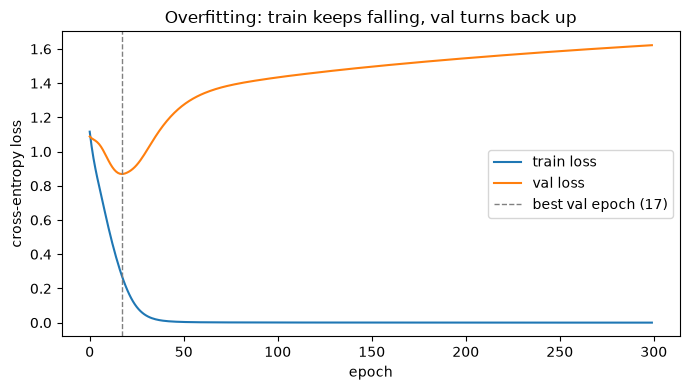

best val loss 0.8691 at epoch 17, final val loss 1.6219 at epoch 299


In [18]:
import matplotlib


best_epoch = int(torch.tensor(va_hist).argmin())

plt.figure(figsize=(7, 4))
plt.plot(tr_hist, label="train loss")
plt.plot(va_hist, label="val loss")
plt.axvline(best_epoch, color="gray", linestyle="--", linewidth=1,
            label=f"best val epoch ({best_epoch})")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Overfitting: train keeps falling, val turns back up")
plt.legend()
plt.tight_layout()
plt.show()

print(f"best val loss {va_hist[best_epoch]:.4f} at epoch {best_epoch}, "
      f"final val loss {va_hist[-1]:.4f} at epoch {len(va_hist)-1}")

the val curve bottoming out and turning back up (around the dashed line) **is** the overfitting
signature -- that's the point where you'd want the saved weights from
(early stopping / checkpoint-at-best-val), not the weights from the final epoch.

In [ ]:
# Count what it got right
# Accuracy is the share of examples the model labels correctly - i.e. the 
# class with the highest logit, compared to the true label

accuracy = (logits.argmax(1) == y).float().mean()

# logits.argmax(1) picks the highest scoring class per example

## Debugging: Shapes, Devices, Gradients (video 13)
1. stack trace - botom up
2. shape mismatch
3. device mismatch
4. when `.grad` is `None`


In [ ]:
a = torch.ones([2, 3])
b = torch.randn([2, 3])

# a @ b # RuntimeError: mat1 and mat2 shapes cannot be multiplied (2x3 and 2x3)
# they need to be (2, 3) and (3, 2) - share an inner dimension
print(a.shape, b.shape)

assert a.shape[-1] == b.shape[0], "inner dims must match"

assert a.device == b.device, "tensors on different devices"

### when .grad is None
- forgot requires_grad
- called zero_grad() fter backward
- don't .detach()

## Save, Load and Use a Model (video 14)

- state_dict
- torch.save(..)
- torch.load(..)
- load_state_dict.  Then switch to model.eval() and predict


In [ ]:

# get the state dictionary
model.state_dict() --> {.....}

# save it to a file
torch.save(model.state_dict(), 'model.pt')

# built the mode from a file
fresh = nn.Sequential(
    nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)
)

fresh.load_state_dict(torch.load('model.pt', map_location='cpu'))
fresh.eval()

with torch.no_grad():
        logits = fresh(one.unsqueeze(0)) # ads the batch dimension
pred = logits.argmax(1).item() # the [redicted class]


## Project: Fashion-MNIST Classifier ! (video 15)

1. data

    `Fashion MNIST as a Dataset`

2. DataLoader 

    `shuffled batches of 64`

3. model

    `a plain MLP, 784-> 256 -> 10`

4. loss

    `cross-entropy on raw logits`

5. optimizer and loop

    `Adam, the training loop ring`

6.  evaluate and save

    `test accuracy, the save the state_dict`



In [1]:
#
# 1.) use torchvision to get the dataset
#
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader

data_dir = '/Users/mshimer/data'

train_data = datasets.FashionMNIST(
      root=data_dir,        # where to save/look for the data on disk
      train=True,           # training split (60,000 images)
      download=True,        # fetch it if it's not already at root
      transform=ToTensor(), # PIL image -> float tensor in [0,1], shape (1, 28, 28)
)

test_data = datasets.FashionMNIST(
      root=data_dir,
      train=False,          # test split (10,000 images)
      download=True,
      transform=ToTensor(),
)

print("len(train_data):", len(train_data))      # 60000
img, label = train_data[0]
print("img.shape:", img.shape)                  # torch.Size([1, 28, 28])  -- 1 channel, grayscale
print("label:", label)                          # int, 0-9
print("train_data.classes", train_data.classes) # ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                                                #  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# 2.) put data into a DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_data,  batch_size=64, shuffle=False)



len(train_data): 60000
img.shape: torch.Size([1, 28, 28])
label: 9
train_data.classes ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [3]:
                                    
# 3. build the MLP - dont forget to nn.Flatten() the images!

model = nn.Sequential(
      nn.Flatten(),          # (B, 1, 28, 28) -> (B, 784)
      nn.Linear(784, 128),
      nn.ReLU(),
      nn.Linear(128, 10),    # the 10 output logits - the prediction
      # no softmax on the end - the cross-entropy handles that
)

# pass in raw logits
ce  = nn.CrossEntropyLoss()

opt = torch.optim.Adam(model.parameters(), lr=1e-3)   # no weight_decay -- nothing fighting the overfit


In [4]:
N_EPOCHS = 5   # one full pass over all 60,000 training images = 1 epoch

tr_hist, va_hist, va_acc_hist = [], [], []

for epoch in range(N_EPOCHS):

    # ---- TRAIN: one full pass over every training batch ----
    model.train()
    running_loss, n_seen = 0.0, 0
    for x_train, y_train in train_loader:
        logits = model(x_train)
        loss = ce(logits, y_train)   # cross_entropy for classification - pass logits!
        opt.zero_grad()
        loss.backward()
        opt.step()

        # loss.item() is the MEAN loss for this batch -- weight it back by batch
        # size before summing, so a smaller last batch doesn't get equal say
        running_loss += loss.item() * x_train.size(0)
        n_seen += x_train.size(0)

    epoch_train_loss = running_loss / n_seen
    tr_hist.append(epoch_train_loss)   # ONE point per epoch, not per batch

    # ---- EVAL: one full pass over ALL 10,000 test images ----
    model.eval()
    val_running_loss, val_correct, val_seen = 0.0, 0, 0
    with torch.no_grad():
        for x_test, y_test in test_loader:
            test_logits = model(x_test)
            batch_loss = ce(test_logits, y_test)

            val_running_loss += batch_loss.item() * x_test.size(0)
            val_correct += (test_logits.argmax(1) == y_test).sum().item()
            val_seen += x_test.size(0)   # should add up to 10,000 by the end

    epoch_val_loss = val_running_loss / val_seen
    epoch_val_acc = val_correct / val_seen
    va_hist.append(epoch_val_loss)
    va_acc_hist.append(epoch_val_acc)

    print(f"epoch {epoch:>2} | train loss {epoch_train_loss:.4f} | "
          f"val loss {epoch_val_loss:.4f} | val acc {epoch_val_acc:.4f}  "
          f"(validated on {val_seen} test rows)")

epoch  0 | train loss 0.5438 | val loss 0.4413 | val acc 0.8451  (validated on 10000 test rows)


epoch  1 | train loss 0.3958 | val loss 0.4153 | val acc 0.8480  (validated on 10000 test rows)


epoch  2 | train loss 0.3563 | val loss 0.3918 | val acc 0.8626  (validated on 10000 test rows)


epoch  3 | train loss 0.3286 | val loss 0.4006 | val acc 0.8559  (validated on 10000 test rows)


epoch  4 | train loss 0.3099 | val loss 0.3528 | val acc 0.8720  (validated on 10000 test rows)


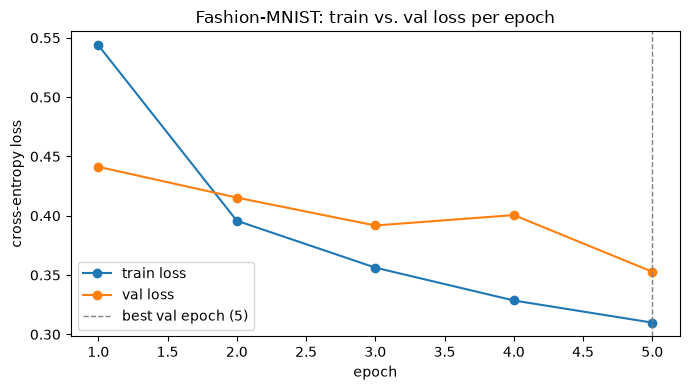

best val loss 0.3528 (acc 0.8720) at epoch 5


In [5]:
import matplotlib.pyplot as plt

best_epoch = int(torch.tensor(va_hist).argmin())

plt.figure(figsize=(7, 4))
plt.plot(range(1, N_EPOCHS + 1), tr_hist, marker="o", label="train loss")
plt.plot(range(1, N_EPOCHS + 1), va_hist, marker="o", label="val loss")
plt.axvline(best_epoch + 1, color="gray", linestyle="--", linewidth=1,
            label=f"best val epoch ({best_epoch + 1})")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Fashion-MNIST: train vs. val loss per epoch")
plt.legend()
plt.tight_layout()
plt.show()

print(f"best val loss {va_hist[best_epoch]:.4f} (acc {va_acc_hist[best_epoch]:.4f}) "
      f"at epoch {best_epoch + 1}")

In [25]:

# save the weights to a file !

torch.save(model.state_dict(), 'fashion_mlp.pt')

### Appendix : Broadcasting

📏 The Rules of BroadcastingTwo tensors are "broadcastable" if you align their shapes starting from the trailing (rightmost) dimension and work your way backward. 

For each dimension, the sizes must meet one of these conditions:

1.) They are equal.

2.)  One of the dimensions is 1.

3.) The dimension does not exist in one of the tensors (meaning one tensor has fewer total dimensions).

How PyTorch Evaluates and Fills Shapes

- Step 1: If one tensor has fewer dimensions than the other, PyTorch prepends 1s to its left side until both shapes have the same length.

- Step 2: For any dimension where one tensor has a size of 1, PyTorch virtually replicates that dimension to match the larger size.

```python
import torch

# Shape: (2, 3)
x = torch.tensor([[1, 2, 3], 
                  [4, 5, 6]])

# Shape: (3,) -> Will be prepended with 1 to become (1, 3)
y = torch.tensor([10, 20, 30])

# PyTorch stretches y's shape from (1, 3) to match x's shape (2, 3)
result = x + y

print(result)
# Output:
# tensor([[11, 22, 33],
#         [14, 25, 36]])
```